Choose a sample to run. `sample_id` can be one of:
- mouse_vas_deferens1
- mouse_vas_deferens2
- mouse_femoral_artery
- mouse_bladder
- mouse_trachea
- human_cornea
- insect_leg

In [ ]:
max_angle = 60
interval = 6
n_bscans = int(max_angle/interval)*2+1
anglename = str(max_angle) + '-' + str(interval) + '-' + str(max_angle)

# sample_id = 'mouse_vas_deferens1'  # a string that denotes which data to run
sample_id = 'phantom'  # a string that denotes which data to run

data_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/Datasets/' + anglename + '/'  # where is the OCRT input data located?
save_directory = 'c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/saved_models_and_variables/' + anglename + '/'  # where to save the tf graph after optimization

# Registration of multiangle B-scans and synthesis of refractive index map
The registration metric is optimized with respect to the deformation model, which in this case is ray propagation through a spatially inhomogeneous refractive index map.

In [2]:
from __future__ import print_function, division
import OCRT
import importlib
importlib.reload(OCRT)
from OCRT import OCRT2D
import numpy as np

import tensorflow as tf
tf.compat.v1.disable_eager_execution()
import matplotlib.pyplot as plt
import numpy as np
from time import time
%matplotlib inline

a = OCRT2D(sample_id=sample_id,save_directory=save_directory)

In [3]:
# adjust some parameters, depending on the sample:
if sample_id in ['mouse_bladder', 'mouse_femoral_artery', 'mouse_trachea', 'mouse_vas_deferens1']:
    num_iter = 200
elif sample_id in ['mouse_vas_deferens2']:
    num_iter = 300
elif sample_id in ['insect_leg']:
    num_iter = 500
elif sample_id in ['human_cornea']:
    num_iter = 500
    # this sample is more difficult to register, so use a multiresolution approach:
    a.use_multires = True
    a.size_factor_ = 1  # the final size_factor_ is 8
    a.switch_iter = 250
elif sample_id in ['phantom']:
    num_iter = 1
else:
    raise Exception('invalid sample_id: ' + sample_id)
    
# two tube sizes were used (same inner diameter, but different outer diameter):
if sample_id in ['mouse_vas_deferens1', 'mouse_vas_deferens2', 'mouse_trachea']:
    a.tube_diameter = 1.066  # in mm
elif sample_id in ['phantom']:
    a.tube_diameter = 0
    a.tube_present = False
    a.knownRI = True
    a.use_parametric_optimization = False
    a.n_back = 1
    a.use_spatial_shifts = False
else:
    a.tube_diameter = 1.108516

In [4]:
a.load_data_and_resolve_constants(data_directory=data_directory, max_angle = max_angle, angle_step = interval)
a.build_graph()

data loaded: 7.144750595092773 sec
Instructions for updating:
Use `tf.cast` instead.
Instructions for updating:
Use `tf.cast` instead.
Instructions for updating:
Use `tf.cast` instead.
graph built: 8.226473093032837 sec


0 [1.0901897, 0.0, 0.0005770487] 82.50998210906982
0


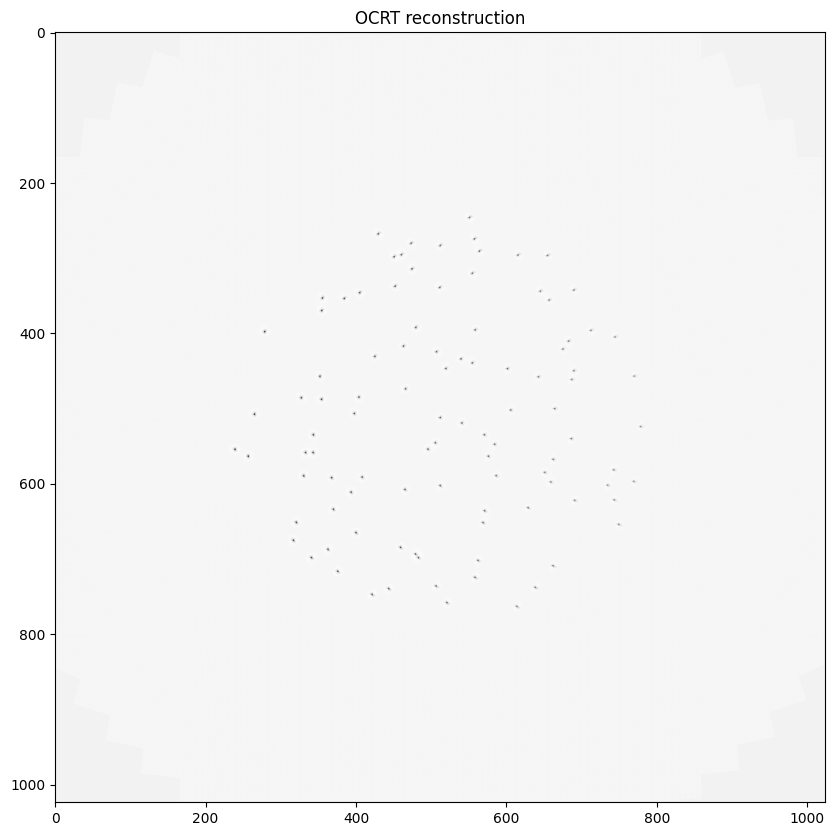

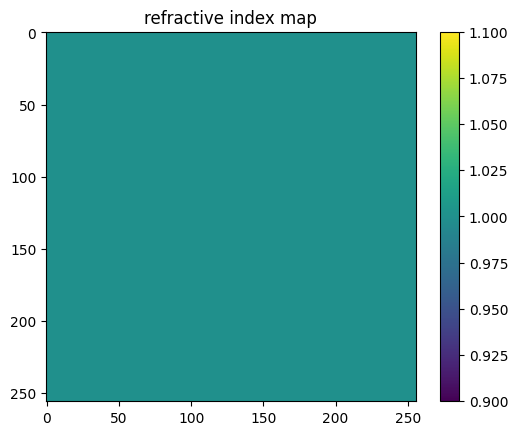

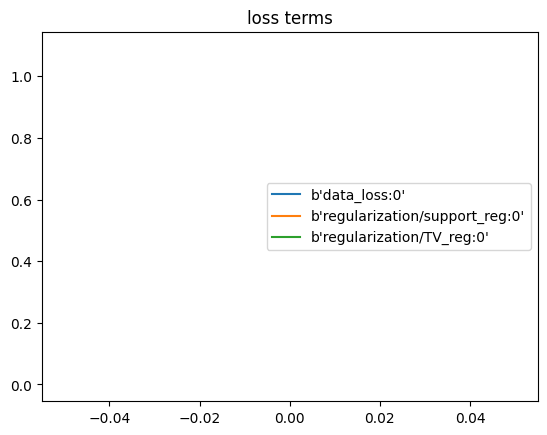

1 [1.0775275, 0.0, 0.0005770487] 72.38790822029114
1


In [5]:
# run through optimization loop:
losses = list()
feed_dict = a.get_feed_dict()
for i in range(num_iter + 1):
    
    # if using multires, change the pixel resolution of the reconstruction
    if i == a.switch_iter and a.use_multires: 
        feed_dict[a.size_factor] = a.final_size_factor
    
    start = time()
    loss_i, _ = a.sess.run([a.loss_terms, a.train_op], feed_dict=feed_dict)
    losses.append(loss_i)
    print(i, loss_i, time()-start)
    # loss_i is a list of all the contributors to the scalar loss;
    # (see a.loss_terms or a.loss_term_names for names of the regularization terms)
    print(i)
    # monitor results periodically:
    if i % 10 == 0:
        recon_i = a.sess.run(a.recon, feed_dict=feed_dict)
        recon_i = recon_i.sum(2)  # only once slice along y contains nonzero values, because we are optimizing 2D
        plt.figure(figsize=(10, 10))
        plt.imshow(recon_i, cmap='gray_r')
        plt.title('OCRT reconstruction')
        plt.show()
        
        RI = a.sess.run(a.RI, feed_dict={a.xz_delta: np.zeros((n_bscans, 2))})  # remove xy_delta shifts
        
        plt.imshow(RI)
        plt.title('refractive index map')
        plt.colorbar()
        plt.show()
        
        plt.plot(losses)
        plt.legend(a.loss_term_names.eval())
        plt.title('loss terms')
        plt.show()

In [6]:
a.save_graph()  # this graph must be saved in order to run filter optimization below

Created new directory: c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/saved_models_and_variables/90-6-90/phantom


# Filter optimization after registration
Freeze the registration/refractive index parameters and only optimize the 2D backprojection filter.

In [7]:
# remove previous tf graph and variables:
a.sess.close()
tf.compat.v1.reset_default_graph()
del a

In [8]:
# # Run during debugs when OCRT.py has been changed
# import OCRT
# import importlib
# importlib.reload(OCRT)
# from OCRT import OCRT2D

In [9]:
# instantiate new object, this time for filter optimization
a = OCRT2D(sample_id=sample_id,save_directory=save_directory)
num_iter = 100
a.infer_backprojection_filter = True
a.use_spatial_shifts = False

# as above, set the tube diameter depending on the sample:
if sample_id in ['mouse_vas_deferens1', 'mouse_vas_deferens2', 'mouse_trachea']:
    a.tube_diameter = 1.066
elif sample_id in ['phantom']:
    a.tube_diameter = 0
    a.tube_present = False
    a.knownRI = True
    a.use_parametric_optimization = False
    a.n_back = 1.35 
else:
    a.tube_diameter = 1.108516

a.load_data_and_resolve_constants(data_directory=data_directory, max_angle = max_angle, angle_step = interval)
a.build_graph()

data loaded: 8.170401096343994 sec
INFO:tensorflow:Restoring parameters from c:/Users/DEL-AIProjects/Documents/GitHub/limited_angle_ocrt_local_saves/saved_models_and_variables/90-6-90/phantom/model.ckpt
graph built: 11.728647470474243 sec


0 [1.0647016, 0.0024846871] 100.85580682754517


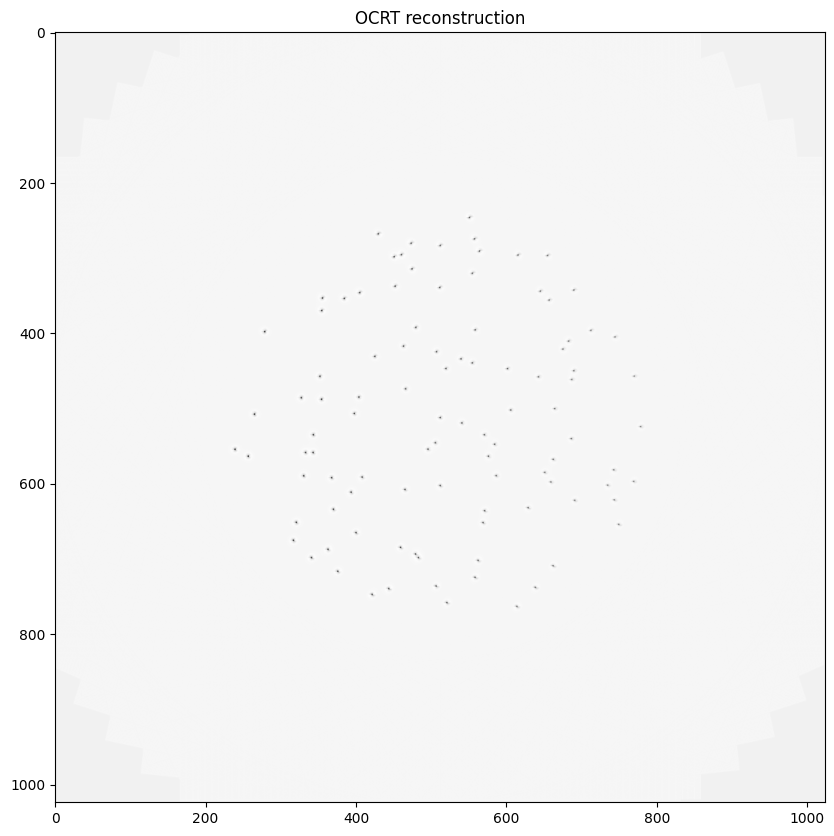

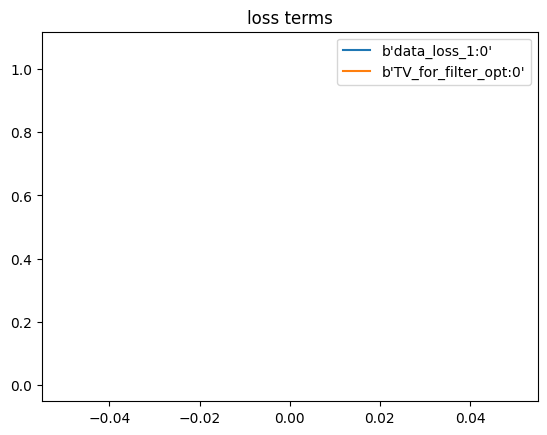

1 [1.0530745, 0.0025389947] 97.3221447467804
2 [1.0415133, 0.002593241] 101.32928442955017
3 [1.0300204, 0.002647576] 102.19322609901428
4 [1.0185966, 0.0027020306] 104.78952240943909
5 [1.0072438, 0.0027565965] 103.72870969772339
6 [0.99596274, 0.00281125] 105.27454257011414
7 [0.98475486, 0.0028659613] 103.5013062953949
8 [0.9736207, 0.002920701] 106.42589497566223
9 [0.96256226, 0.00297544] 108.69880962371826
10 [0.9515795, 0.0030301535] 108.52569460868835
11 [0.9406735, 0.0030848205] 109.15604519844055
12 [0.9298457, 0.0031394227] 108.97200798988342
13 [0.91909635, 0.003193944] 109.1824951171875
14 [0.9084265, 0.0032483719] 109.49305534362793
15 [0.8978366, 0.003302694] 108.24382495880127
16 [0.88732773, 0.0033569043] 110.61840271949768
17 [0.8769002, 0.0034109927] 110.2935905456543
18 [0.8665546, 0.0034649551] 111.06079387664795
19 [0.85629165, 0.0035187863] 111.30634617805481
20 [0.8461118, 0.0035724812] 111.8561680316925


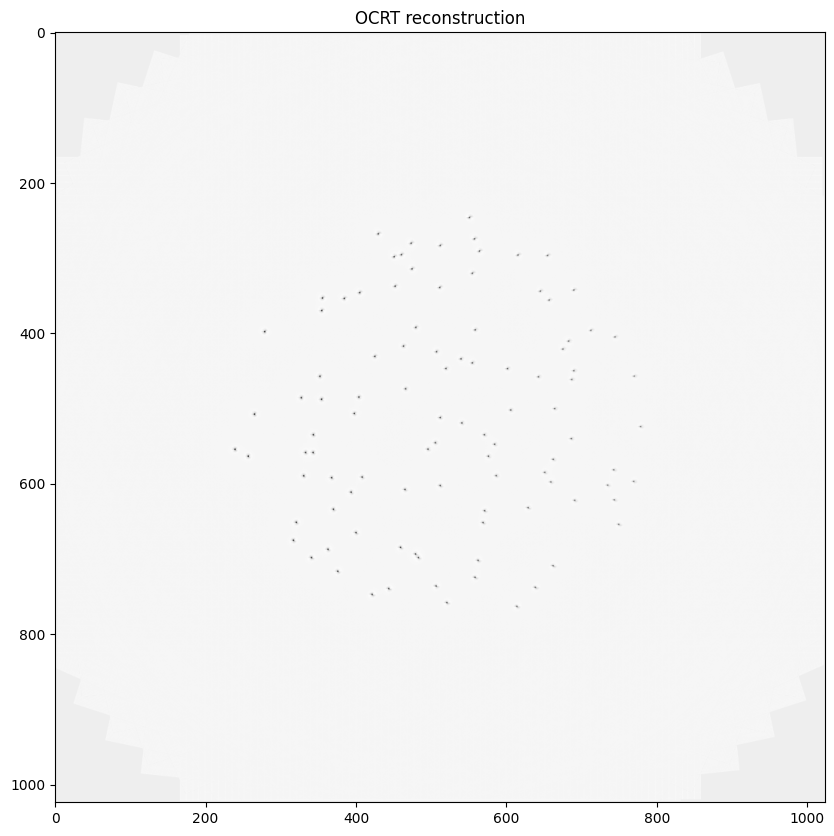

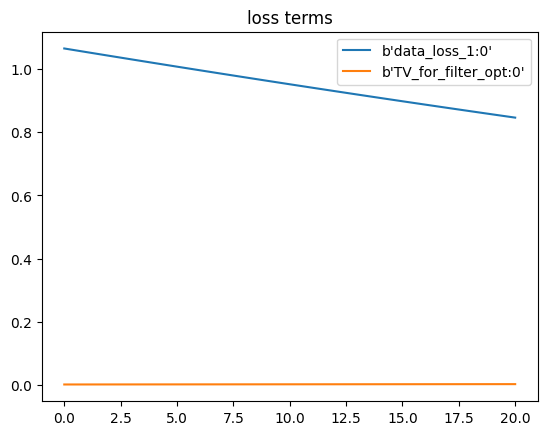

21 [0.83601534, 0.0036260372] 112.97928309440613
22 [0.82600266, 0.0036794478] 111.58341455459595
23 [0.81607455, 0.0037327125] 110.82162952423096
24 [0.8062308, 0.0037858265] 112.59604954719543
25 [0.7964717, 0.003838788] 113.67910194396973
26 [0.78679764, 0.0038915933] 112.73572659492493
27 [0.7772089, 0.0039442405] 112.1180489063263
28 [0.76770544, 0.0039967266] 113.37442827224731
29 [0.75828743, 0.0040490497] 112.31114315986633
30 [0.74895495, 0.0041012075] 111.49594712257385
31 [0.7397079, 0.0041531967] 110.35889935493469
32 [0.7305464, 0.0042050155] 111.87712407112122
33 [0.72147036, 0.0042566634] 110.46360421180725
34 [0.7124797, 0.0043081357] 111.03336071968079
35 [0.7035744, 0.0043594325] 110.76391744613647
36 [0.6947542, 0.0044105505] 111.03753924369812
37 [0.686019, 0.0044614896] 111.10828900337219
38 [0.6773689, 0.004512247] 110.63426232337952
39 [0.66880316, 0.0045628226] 110.75198292732239
40 [0.66032183, 0.0046132137] 111.64467144012451


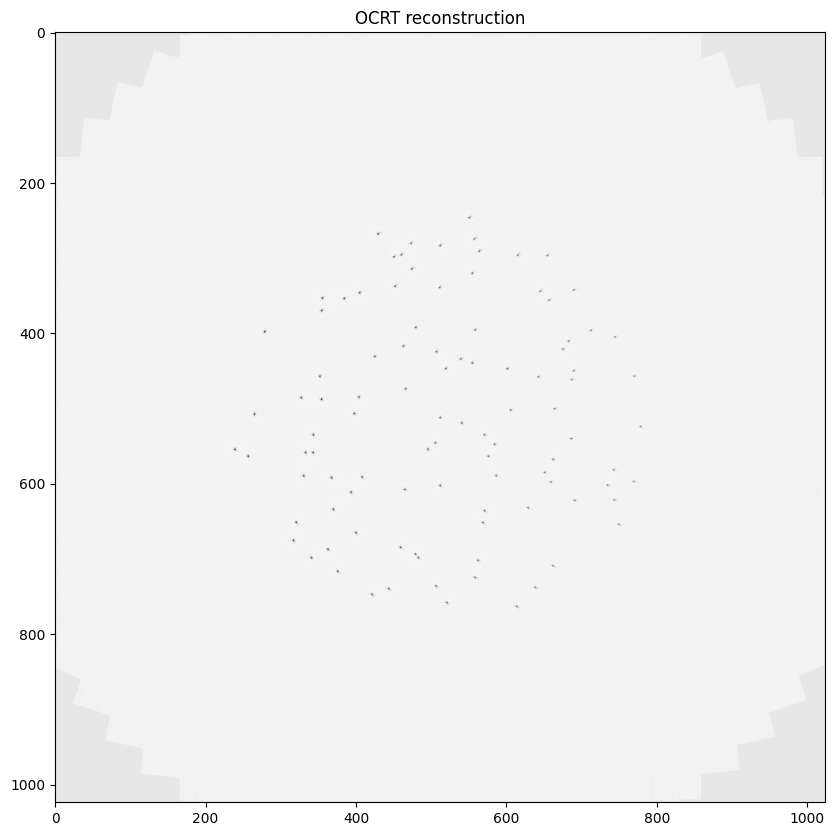

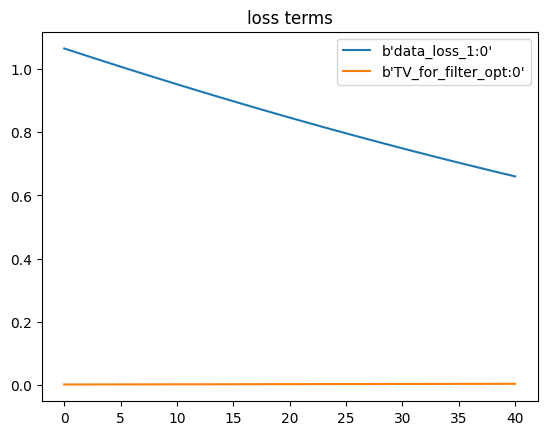

41 [0.6519246, 0.0046634185] 111.438312292099
42 [0.64361125, 0.0047134343] 110.90740180015564
43 [0.6353814, 0.004763263] 110.19340133666992
44 [0.6272348, 0.0048129004] 110.72349810600281
45 [0.61917114, 0.004862347] 111.11267447471619
46 [0.61119, 0.0049116034] 109.88054370880127
47 [0.60329103, 0.004960665] 111.54552817344666
48 [0.5954738, 0.005009535] 111.02255606651306
49 [0.5877382, 0.0050582103] 110.45749998092651
50 [0.5800835, 0.0051066885] 110.2593092918396
51 [0.57250935, 0.0051549706] 110.57441854476929
52 [0.5650154, 0.0052030534] 111.3766405582428
53 [0.5576012, 0.0052509373] 111.3495705127716
54 [0.5502663, 0.0052986206] 110.10978889465332
55 [0.5430102, 0.005346103] 111.55843019485474
56 [0.53583235, 0.005393385] 110.70748662948608
57 [0.5287325, 0.005440463] 110.19859862327576
58 [0.5217101, 0.005487338] 110.37532019615173
59 [0.5147646, 0.00553401] 111.45874905586243
60 [0.50789547, 0.0055804765] 109.78589367866516


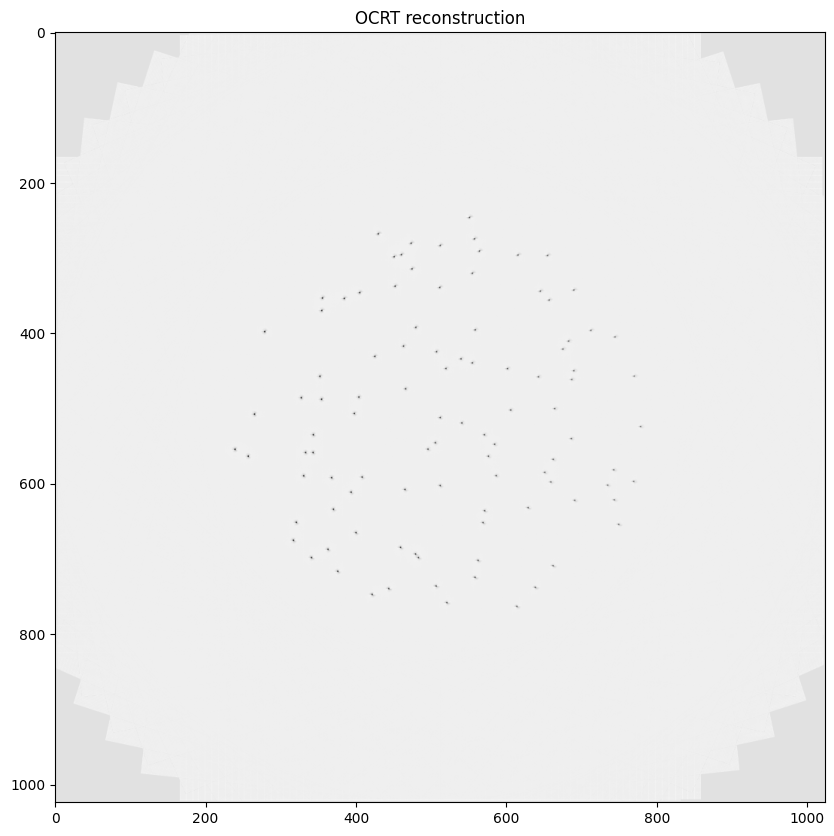

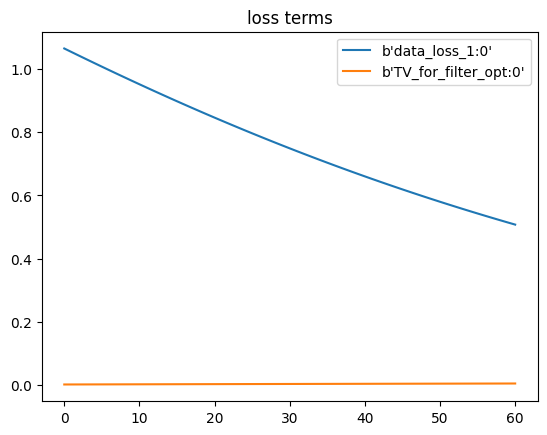

61 [0.50110245, 0.0056267385] 110.5155553817749
62 [0.4943848, 0.0056727948] 110.99079179763794
63 [0.48774207, 0.0057186442] 111.81414723396301
64 [0.48117372, 0.0057642865] 110.94202303886414
65 [0.47467932, 0.005809722] 111.16748571395874
66 [0.46825844, 0.0058549475] 111.30182695388794
67 [0.46191052, 0.005899965] 111.91880416870117
68 [0.4556349, 0.0059447717] 111.7293393611908
69 [0.44943118, 0.00598937] 111.62999844551086
70 [0.44329867, 0.0060337577] 112.17512321472168
71 [0.43723702, 0.006077936] 110.72545099258423
72 [0.4312457, 0.006121901] 111.1757640838623
73 [0.4253242, 0.0061656553] 110.8962037563324
74 [0.41947186, 0.006209198] 111.3530490398407
75 [0.4136883, 0.006252528] 110.92619323730469
76 [0.4079728, 0.006295646] 110.94130086898804
77 [0.40232494, 0.006338552] 110.63333487510681
78 [0.39674428, 0.0063812467] 110.61910772323608
79 [0.39123017, 0.0064237295] 112.65198159217834
80 [0.38578206, 0.0064660017] 112.0793309211731


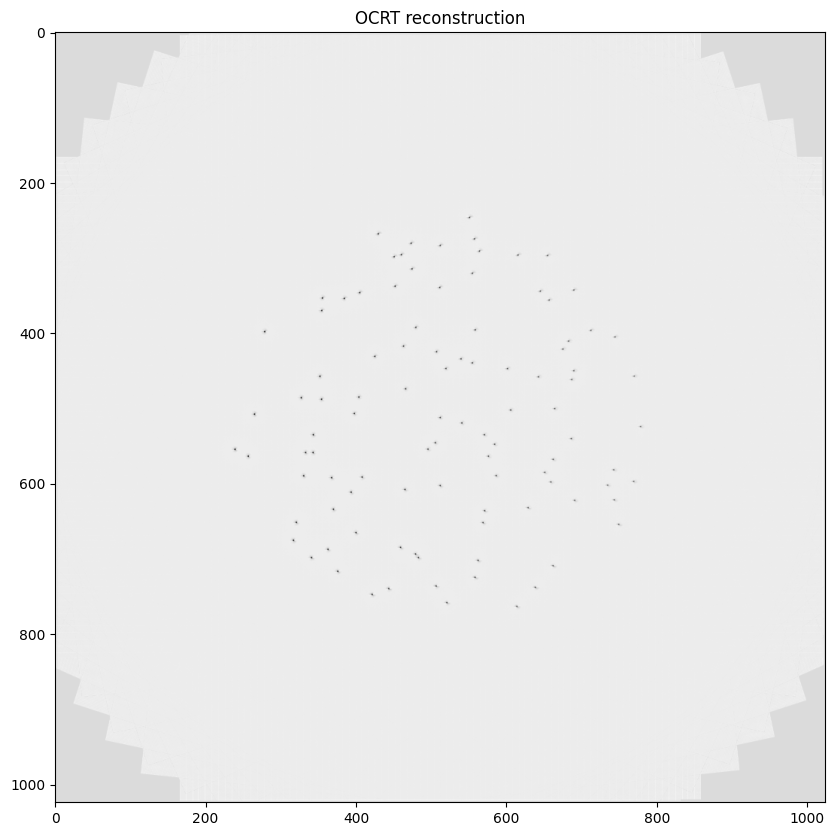

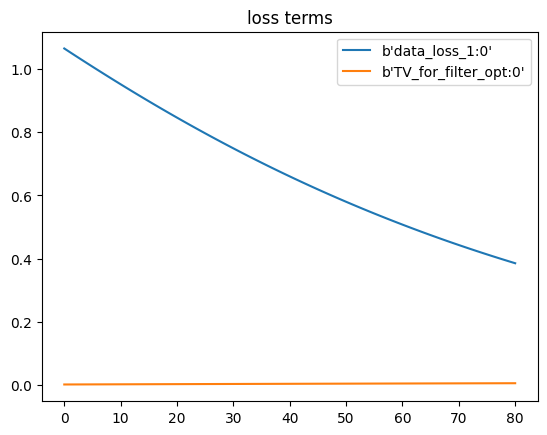

81 [0.38039953, 0.0065080626] 110.92818927764893
82 [0.37508208, 0.0065499116] 110.84683966636658
83 [0.36982897, 0.00659155] 112.35995817184448
84 [0.36463982, 0.0066329776] 111.02209806442261
85 [0.35951406, 0.006674195] 110.38971734046936
86 [0.35445118, 0.0067152022] 110.06806111335754
87 [0.34945065, 0.0067560007] 112.35692286491394
88 [0.3445119, 0.006796588] 111.17001008987427
89 [0.33963457, 0.0068369657] 112.8603925704956
90 [0.3348179, 0.006877135] 110.93227887153625
91 [0.33006147, 0.0069170953] 112.52931118011475
92 [0.3253648, 0.006956846] 111.00252842903137
93 [0.3207273, 0.0069963885] 111.20011353492737
94 [0.31614846, 0.007035723] 111.36067152023315
95 [0.31162786, 0.00707485] 112.05044293403625
96 [0.3071649, 0.0071137687] 111.33129572868347
97 [0.30275905, 0.0071524805] 110.85459184646606
98 [0.29840976, 0.007190987] 111.22443294525146
99 [0.29411662, 0.0072292853] 109.7600634098053
100 [0.28987902, 0.0072673783] 108.93250775337219


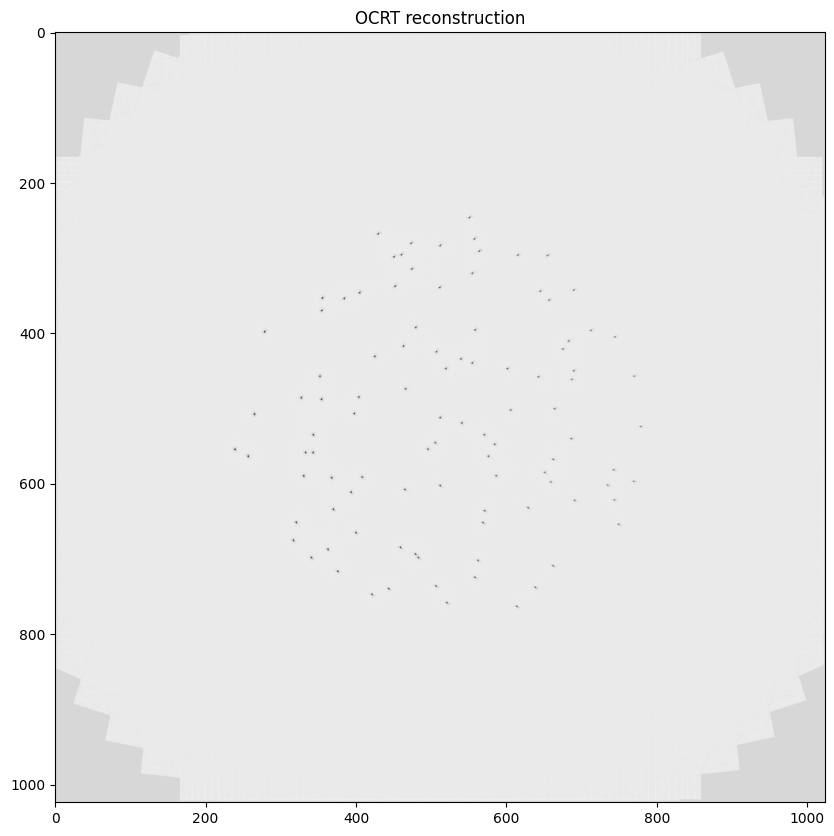

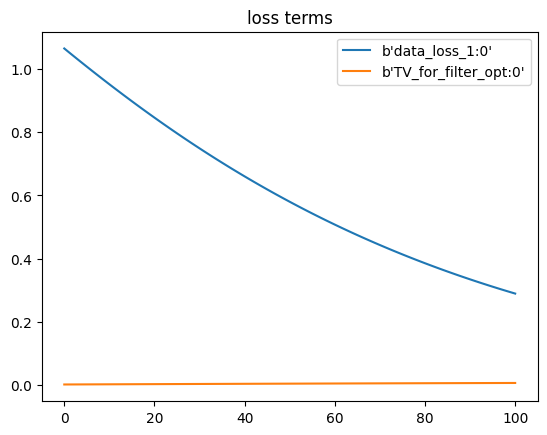

In [10]:
losses = list()
feed_dict = a.get_feed_dict()
for i in range(num_iter + 1):
    start = time()
    loss_i, _ = a.sess.run([a.loss_terms, a.train_op], feed_dict=feed_dict)
    losses.append(loss_i)
    print(i, loss_i, time()-start)
    
    # monitor results periodically:
    if i % 20 == 0:
        recon_i = a.sess.run(a.recon, feed_dict=feed_dict)
        recon_i = recon_i.sum(2)
        plt.figure(figsize=(10, 10))
        plt.imshow(recon_i, cmap='gray_r')
        plt.title('OCRT reconstruction')
        plt.show()
        
        plt.plot(losses)
        plt.legend(a.loss_term_names.eval())
        plt.title('loss terms')
        plt.show()

In [11]:
a.save_graph()  # this graph doesn't need to be saved